# Fase 0 · Detección de arritmias en ECG (MIT-BIH)

Este cuaderno deja listo el entorno y los datos:

1. Instala las librerías y descarga la base MIT-BIH (unos 100 MB, tarda 1 a 3 minutos).
2. Grafica 10 segundos del registro 100 antes y después del filtro.
3. Corta cada latido alrededor del pico R y calcula sus características RR.
4. Separa los pacientes en DS1 (entrenar) y DS2 (probar) según de Chazal et al. (2004).
5. Compara los conteos con los publicados y guarda los datos en un archivo `.npz`.

**Cómo usarlo:** en Colab, *Entorno de ejecución → Ejecutar todas*. Opcionalmente monten Google Drive (celda 2) para no descargar todo cada vez.

In [1]:
!pip install -q wfdb

## 1. Librerías y descarga de datos
Si montan Google Drive, cambien `DATA_DIR` a una carpeta de Drive (por ejemplo `/content/drive/MyDrive/ecg/mitdb`) y la descarga se hace una sola vez.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import wfdb
except ImportError:          # si se saltaron la celda de instalación
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'wfdb'])
    import wfdb
from scipy.signal import butter, filtfilt
from collections import Counter

# from google.colab import drive; drive.mount('/content/drive')   # opcional
DATA_DIR = os.environ.get('MITDB_DIR', 'mitdb')

if not os.path.exists(os.path.join(DATA_DIR, '100.hea')):
    wfdb.dl_database('mitdb', dl_dir=DATA_DIR)

n = len([f for f in os.listdir(DATA_DIR) if f.endswith('.hea')])
print(f'{n} registros en {DATA_DIR}')

48 registros en mitdb


## 2. Constantes del problema
- **Clases AAMI (alcance reducido a 3):** N = normal, S = supraventricular, V = ventricular. Fusión (F) y desconocido (Q) se descartan como muestras, pero sí cuentan para calcular los intervalos RR.
- **Registros excluidos:** 102, 104, 107 y 217 tienen marcapasos.
- **DS1 / DS2:** división inter-paciente de de Chazal et al. (2004). Los pacientes de prueba nunca se ven en entrenamiento.

In [3]:
FS = 360
PRE, POST = 90, 144          # muestras antes y después del pico R (0,25 s y 0,4 s)

AAMI = {**{s: 'N' for s in 'NLRej'},
        **{s: 'S' for s in 'AaJS'},
        **{s: 'V' for s in 'VE'}}
LATIDOS = set('NLRBAaJSVrFejnE/fQ?')   # todos los símbolos que marcan un latido

EXCLUIDOS = ['102', '104', '107', '217']
DS1 = ['101','106','108','109','112','114','115','116','118','119','122',
       '124','201','203','205','207','208','209','215','220','223','230']
DS2 = ['100','103','105','111','113','117','121','123','200','202','210',
       '212','213','214','219','221','222','228','231','232','233','234']

# Conteos publicados (de Chazal et al., 2004) para comparar
ESPERADO = {'DS1': {'N': 45866, 'S': 944, 'V': 3788},
            'DS2': {'N': 44259, 'S': 1837, 'V': 3221}}

# Para pruebas rápidas se puede limitar la lista de registros
if os.environ.get('RECORDS_TEST'):
    DS1 = DS2 = os.environ['RECORDS_TEST'].split(',')
assert not set(DS1) & set(DS2) or os.environ.get('RECORDS_TEST'), 'DS1 y DS2 comparten pacientes'

## 3. Filtro y vista de un registro
Pasa-banda Butterworth de 0,5 a 40 Hz con `filtfilt` (sin desfase): quita la deriva de línea base y el ruido de alta frecuencia sin mover los picos R.

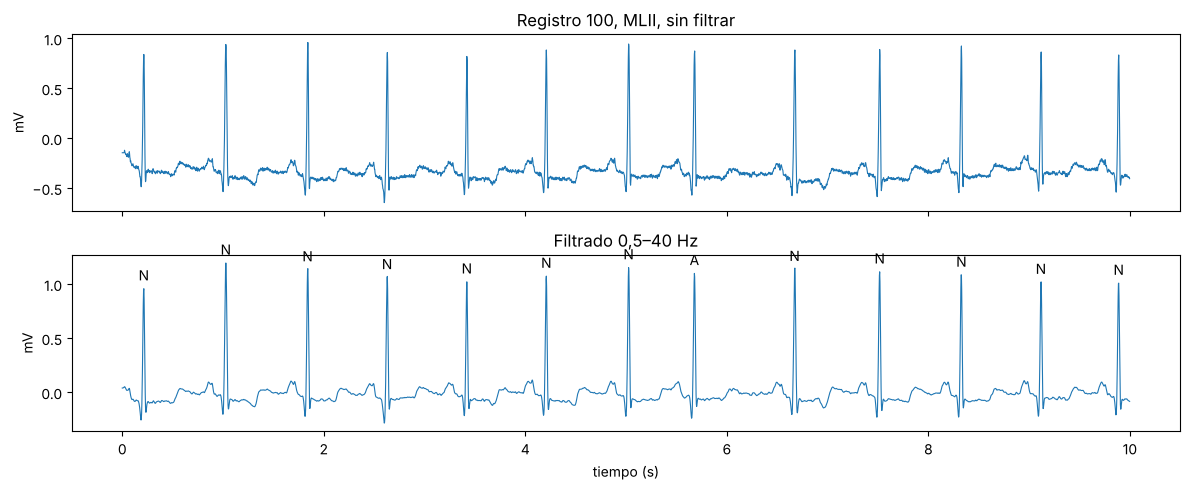

Anotaciones del registro 100: Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})


In [4]:
def filtrar(x, fs=FS):
    b, a = butter(2, [0.5 / (fs / 2), 40 / (fs / 2)], btype='band')
    return filtfilt(b, a, x)

def canal_mlii(rec):
    # En casi todos los registros MLII es el canal 0, pero no en todos (p. ej. 114)
    return rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0

rec = wfdb.rdrecord(os.path.join(DATA_DIR, '100'))
ann = wfdb.rdann(os.path.join(DATA_DIR, '100'), 'atr')
x = rec.p_signal[:, canal_mlii(rec)]
xf = filtrar(x)

n = 10 * FS
t = np.arange(n) / FS
fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axs[0].plot(t, x[:n], lw=0.8); axs[0].set_title('Registro 100, MLII, sin filtrar')
axs[1].plot(t, xf[:n], lw=0.8); axs[1].set_title('Filtrado 0,5–40 Hz')
for r, s in zip(ann.sample, ann.symbol):
    if r < n and s in LATIDOS:
        axs[1].annotate(s, (r / FS, xf[r]), xytext=(0, 6), textcoords='offset points', ha='center')
axs[1].set_xlabel('tiempo (s)')
for ax in axs: ax.set_ylabel('mV')
plt.tight_layout(); plt.show()
print('Anotaciones del registro 100:', Counter(ann.symbol))

## 4. Segmentar latidos y calcular características RR
Por cada latido de clase N, S o V se guarda:
- **Forma:** 234 muestras alrededor del pico R (de −0,25 s a +0,4 s).
- **RR:** intervalo anterior, siguiente, promedio de los últimos 10, y el cociente *RR anterior / RR promedio*. Este cociente es el que delata a los latidos S: llegan antes **respecto al ritmo de ese paciente**.

In [5]:
def procesar_registro(nombre):
    ruta = os.path.join(DATA_DIR, nombre)
    rec = wfdb.rdrecord(ruta)
    ann = wfdb.rdann(ruta, 'atr')
    xf = filtrar(rec.p_signal[:, canal_mlii(rec)])

    sym = np.array(ann.symbol)
    r = np.array(ann.sample)
    es_latido = np.isin(sym, list(LATIDOS))
    r, sym = r[es_latido], sym[es_latido]
    rr = np.diff(r) / FS

    X, F, y = [], [], []
    for i in range(1, len(r) - 1):           # se omiten el primer y el último latido
        if sym[i] not in AAMI:
            continue
        ini, fin = r[i] - PRE, r[i] + POST
        if ini < 0 or fin > len(xf):
            continue
        pre, post = rr[i - 1], rr[i]
        prom = rr[max(0, i - 10):i].mean()
        X.append(xf[ini:fin]); F.append([pre, post, prom, pre / prom]); y.append(AAMI[sym[i]])
    return np.array(X), np.array(F), np.array(y)

def procesar_lista(registros):
    Xs, Fs, ys, ps = [], [], [], []
    for nombre in registros:
        X, F, y = procesar_registro(nombre)
        Xs.append(X); Fs.append(F); ys.append(y); ps.append(np.full(len(y), nombre))
    return (np.vstack(Xs).astype(np.float32), np.vstack(Fs).astype(np.float32),
            np.concatenate(ys), np.concatenate(ps))

X1, F1, y1, p1 = procesar_lista(DS1)
X2, F2, y2, p2 = procesar_lista(DS2)
print('DS1:', X1.shape, F1.shape, '| DS2:', X2.shape, F2.shape)

DS1: (50555, 234) (50555, 4) | DS2: (49273, 234) (49273, 4)


## 5. Verificar los conteos
Deben quedar muy cerca de los publicados. Salen unos pocos menos porque se omiten el primer y el último latido de cada registro.

In [6]:
filas = []
for nombre, y in [('DS1', y1), ('DS2', y2)]:
    c = Counter(y)
    for clase in 'NSV':
        filas.append({'conjunto': nombre, 'clase': clase, 'obtenido': c[clase],
                      'publicado': ESPERADO[nombre][clase],
                      'diferencia': c[clase] - ESPERADO[nombre][clase]})
tabla = pd.DataFrame(filas)
display(tabla) if 'display' in globals() else print(tabla)
print(f"Porcentaje de latidos S en DS1: {100 * np.mean(y1 == 'S'):.1f} %  <- por esto no sirve la exactitud como métrica")

  conjunto clase  obtenido  publicado  diferencia
0      DS1     N     45824      45866         -42
1      DS1     S       943        944          -1
2      DS1     V      3788       3788           0
3      DS2     N     44218      44259         -41
4      DS2     S      1836       1837          -1
5      DS2     V      3219       3221          -2
Porcentaje de latidos S en DS1: 1.9 %  <- por esto no sirve la exactitud como métrica


## 6. Latido promedio por clase y separación por RR
La primera figura muestra por qué S es difícil: su forma promedio casi coincide con la normal. La segunda muestra que el cociente RR sí ayuda, pero las clases se traslapan: no hay una recta que las separe.

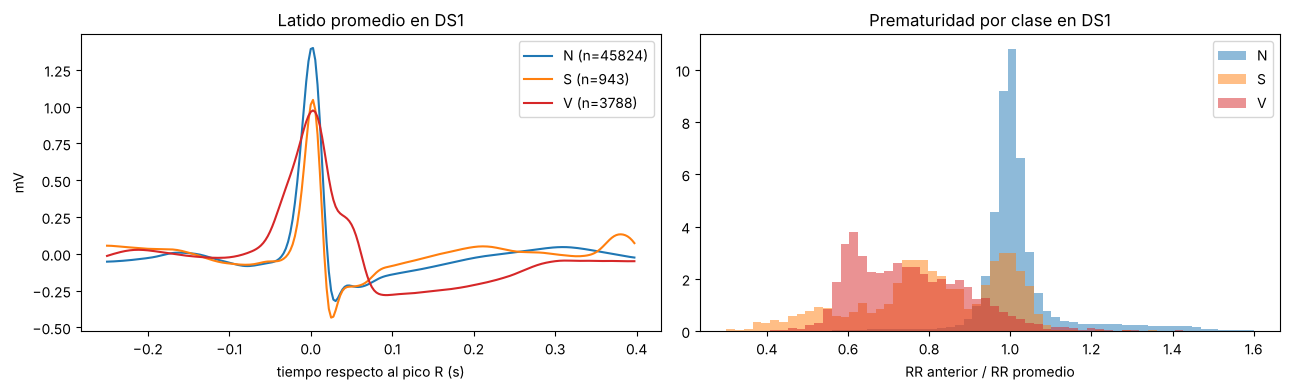

In [7]:
tt = (np.arange(PRE + POST) - PRE) / FS
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for clase, color in zip('NSV', ['tab:blue', 'tab:orange', 'tab:red']):
    m = y1 == clase
    if m.any():
        axs[0].plot(tt, X1[m].mean(0), color=color, label=f'{clase} (n={m.sum()})')
        axs[1].hist(F1[m, 3], bins=60, range=(0.3, 1.6), density=True, alpha=0.5, color=color, label=clase)
axs[0].set_xlabel('tiempo respecto al pico R (s)'); axs[0].set_ylabel('mV'); axs[0].set_title('Latido promedio en DS1'); axs[0].legend()
axs[1].set_xlabel('RR anterior / RR promedio'); axs[1].set_title('Prematuridad por clase en DS1'); axs[1].legend()
plt.tight_layout(); plt.show()

## 7. Guardar los datos procesados
Un solo archivo con todo. En la fase 2 se carga con `np.load('mitbih_ds1_ds2.npz')`. `p1` y `p2` guardan el paciente de cada latido, necesario para separar la validación por pacientes.

In [8]:
np.savez_compressed('mitbih_ds1_ds2.npz', X1=X1, F1=F1, y1=y1, p1=p1, X2=X2, F2=F2, y2=y2, p2=p2)
print('Guardado:', os.path.getsize('mitbih_ds1_ds2.npz') / 1e6, 'MB')

Guardado: 84.169687 MB
